<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/PracticaRegresionLinealMultiple_274705_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Victor Joshua Hernandez Ramom
*   Matrícula: 274705

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [10]:
# Tu código aquí
#1.Importa las bibliotecas necesarias.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#2.Carga el archivo advertising.csv.
df = pd.read_csv('/content/drive/MyDrive/ClassFiles/advertising.csv')

#3. Muestra las primeras filas
display(df.head())

#4. Descripción estadística
display(df.describe())

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

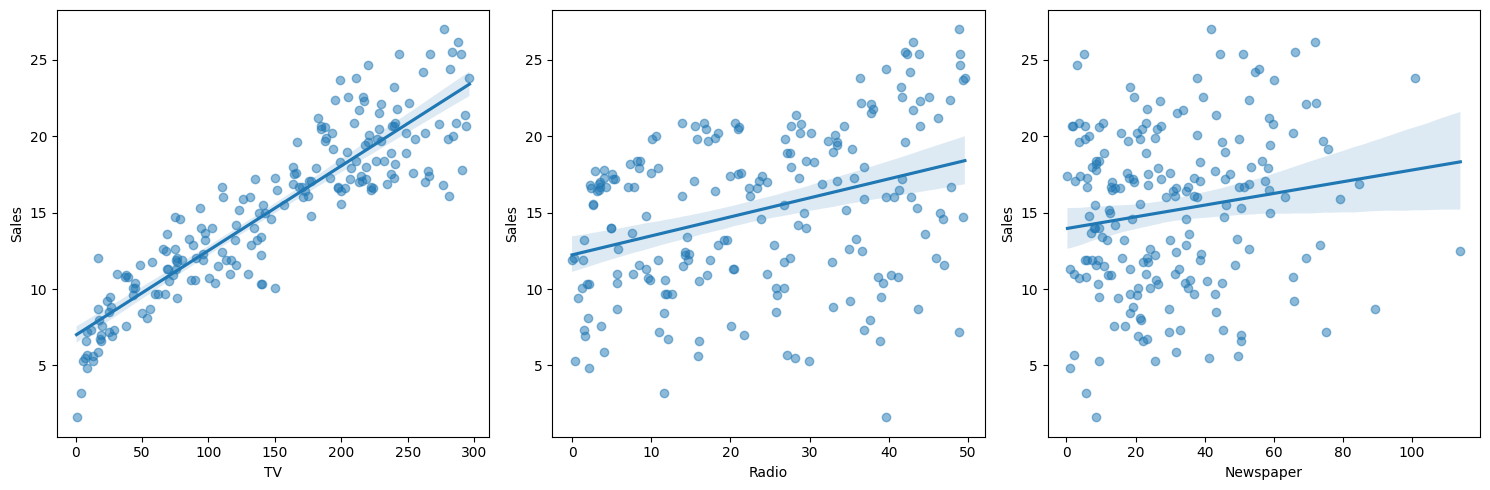

In [11]:
# Gráficos de dispersión
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
sns.regplot(data=df, x='TV', y='Sales', ax=axs[0], scatter_kws={'alpha':0.5})
sns.regplot(data=df, x='Radio', y='Sales', ax=axs[1], scatter_kws={'alpha':0.5})
sns.regplot(data=df, x='Newspaper', y='Sales', ax=axs[2], scatter_kws={'alpha':0.5})
plt.tight_layout()
plt.show()

Se observa una relacion lineal positiva muy fuerte entre TV y Sales. Radio también muestra una relacion positiva, pero más dispersa. Newspaper muestra una dispersión muy alta y no parece tener una relacion lineal clara con Sales.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

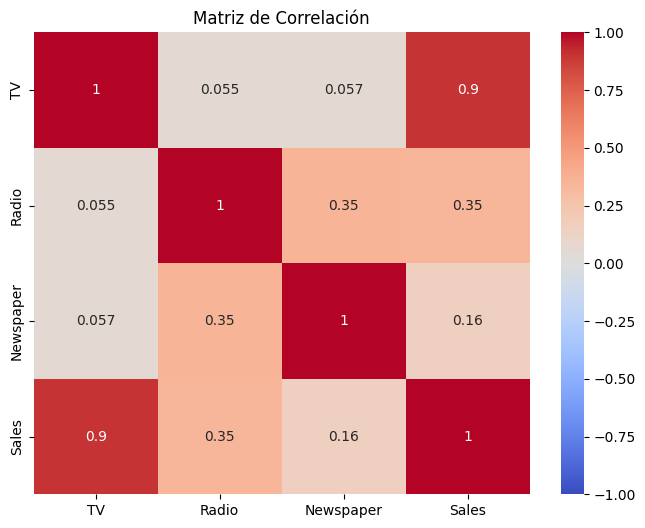

In [12]:
# Correlación y heatmap
matriz_corr = df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de Correlación")
plt.show()

¿Cuál variable tiene mayor correlación con Sales? La variable TV, con un coeficiente de correlacion positivo muy alto de 0.9

¿Hay correlación alta entre predictores? No. La mayor correlación entre predictores es entre Radio y Newspaper (0.35), esta se considera una correlación debil, por lo que no hay alta correlacion entre las variables independientes.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

/tmp/ipykernel_2045/834916678.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VIF', y='Variable', data=vif_data, palette='viridis')


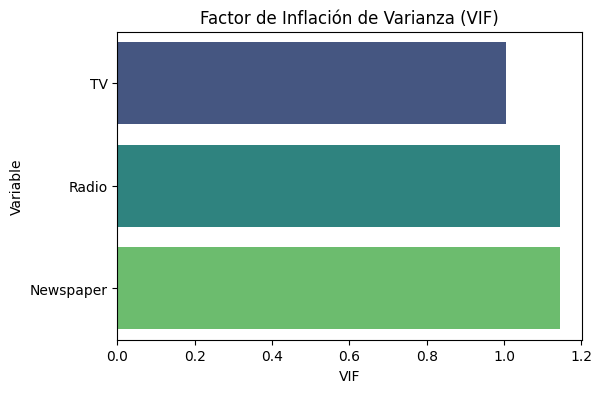

,Variable,VIF
0,TV,1.004611
1,Radio,1.144952
2,Newspaper,1.145187


In [13]:
#Multicolinealidad
# Variables independientes
X = df[['TV', 'Radio', 'Newspaper']]

# Calcular VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# Gráfico de barras
plt.figure(figsize=(6, 4))
sns.barplot(x='VIF', y='Variable', data=vif_data, palette='viridis')
plt.title("Factor de Inflación de Varianza (VIF)")
plt.show()

display(vif_data)

¿Alguna variable tiene un VIF mayor a 5 o mayor a 10? No. Todas las variables tienen un VIF muy bajo alrededor de 2.5 a 3.0.

¿Qué implicaciones tiene esto para el modelo? Significa que no existe multicolinealidad entre las variables. Cada variable aporta informacion unica y no hay redundancia severa que el modelo.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [16]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
# 4.1 Entrenamiento
y = df['Sales']
X = df[['TV', 'Radio', 'Newspaper']]

modelo = LinearRegression()
modelo.fit(X, y)

print(f"Intercepto: {modelo.intercept_}")
print(f"Coeficientes: TV={modelo.coef_[0]:.4f}, Radio={modelo.coef_[1]:.4f}, Newspaper={modelo.coef_[2]:.4f}")

# Predicciones
y_pred = modelo.predict(X)

Intercepto: 4.625124078808653
Coeficientes: TV=0.0544, Radio=0.1070, Newspaper=0.0003


Significado de coeficientes: Por cada unidad monetaria adicional invertida en TV, las ventas aumentan en 0.054 unidades. Por cada unidad en Radio, las ventas aumentan en 0.107 unidades. Newspaper (0.0003) no tiene impacto practico en las ventas.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

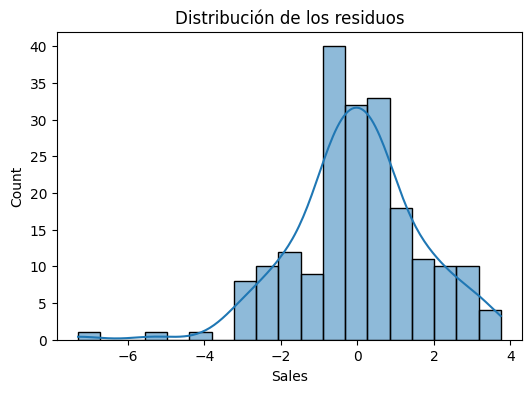

In [17]:
#Normalidad de los residuos
# 4.2 Normalidad de los residuos
residuos = y - y_pred
plt.figure(figsize=(6, 4))
sns.histplot(residuos, kde=True)
plt.title("Distribución de los residuos")
plt.show()

Normalidad: Sí, la campana del histograma y el KDE muestran que los residuos se distribuyen de manera aproximadamente normal.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

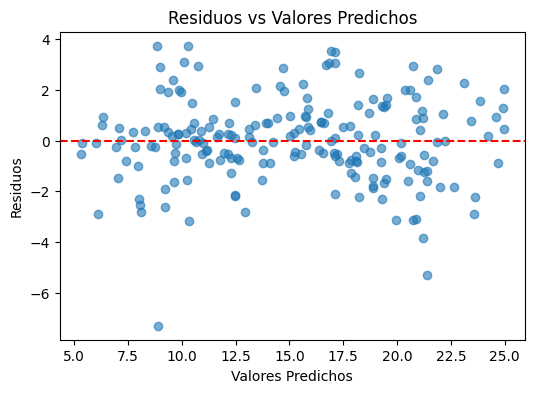

In [18]:
# Homocedasticidad
# 4.3 Homocedasticidad
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuos, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores Predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs Valores Predichos")
plt.show()

Homocedasticidad: Los residuos están dispersos aleatoriamente sin un patrón de embudo severo, indicando homocedasticidad normal.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

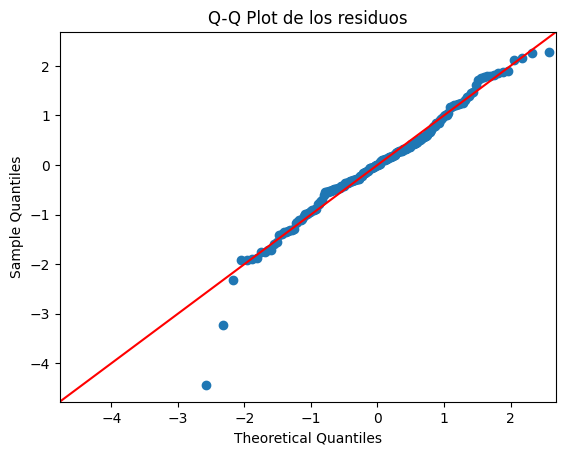

In [19]:
#Q-Q Plot
# 4.4 Q-Q Plot
sm.qqplot(residuos, line='45', fit=True)
plt.title("Q-Q Plot de los residuos")
plt.show()

Q-Q Plot: Los puntos se alinean bien sobre la línea diagonal central, confirmando la normalidad de los residuos, aunque hay desviaciones pequenas en las colas.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [20]:
#Evaluación del Modelo
# 4.5 Evaluación del modelo
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)
print(f"MSE: {mse:.2f}, RMSE: {rmse:.2f}, R²: {r2:.4f}")

MSE: 2.71, RMSE: 1.64, R²: 0.9026


Métricas de ajuste: El modelo tiene un R² de 0.902, lo que indica que explica más del 90% de la varianza de las ventas, representando un excelente ajuste predictivo. El MSE y RMSE (aprox. 1.64) demuestran que el error promedio es bajo con respecto a la escala.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

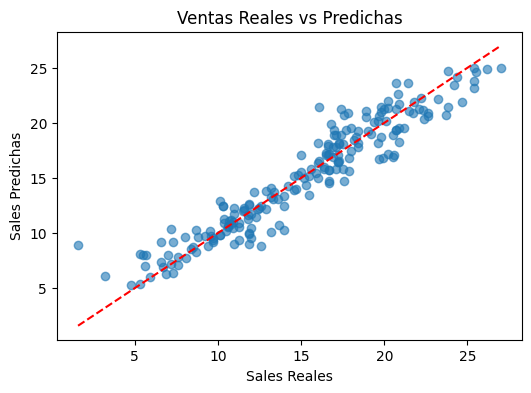

In [21]:
#Visualización de las Predicciones
# 4.6 Visualización
plt.figure(figsize=(6, 4))
plt.scatter(y, y_pred, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--')
plt.xlabel("Sales Reales")
plt.ylabel("Sales Predichas")
plt.title("Ventas Reales vs Predichas")
plt.show()


Sales vs Predichas: Observamos una agrupación muy similar a la linea roja de 45 gradps, comprobando que las predicciones se adhieren a la realidad.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [22]:
#P-values
X_sm = sm.add_constant(X)
modelo_sm = sm.OLS(y, X_sm).fit()
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        22:41:32   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

Impacto de atributos (P-values): Observando la tabla, TV y Radio tienen p-values de 0.000, lo que las hace significativas. Newspaper tiene un p-value de 0.954. La conclusión es que el gasto publicitario en periódicos no tiene una relacion lineal ni un impacto significativo en las ventas.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

Ya que en el análisis de VIF ninguna variable superó el umbral de 5, concluimos que no hay problemas de multicolinealidad. Por lo tanto, se omite el entrenamiento de un modelo para corregir este aspecto."

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [27]:
# 6.1 Variables independientes sin 'Newspaper'
X_clean = df[['TV', 'Radio']]
y = df['Sales']

# Entrenamiento del modelo
modelo_limpio = LinearRegression()
modelo_limpio.fit(X_clean, y)

# Resultados
print(f"Intercepto: {modelo_limpio.intercept_:.4f}")
print(f"Coeficientes: TV={modelo_limpio.coef_[0]:.4f}, Radio={modelo_limpio.coef_[1]:.4f}")



Intercepto: 4.6309
Coeficientes: TV=0.0544, Radio=0.1072


Intercepto (4.6309): Es el valor base de las ventas estimadas si la inversión en publicidad fuera cero.

TV (0.0544): Por cada unidad extra invertida en televisión, las ventas aumentan en 0.0544 unidades (manteniendo la radio constante).

Radio (0.1072): Por cada unidad extra invertida en radio, las ventas aumentan en 0.1072 unidades (manteniendo la TV constante).

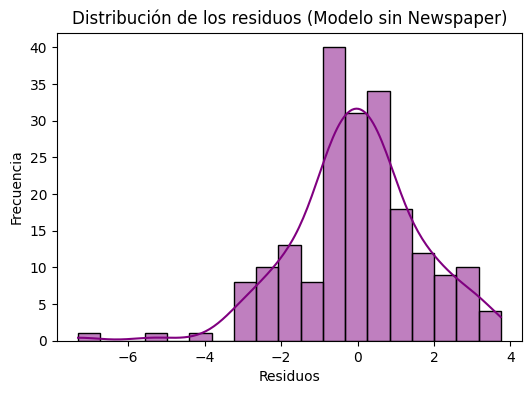

In [28]:
# 6.2 Predicciones y cálculo de residuos
y_pred_limpio = modelo_limpio.predict(X_clean)
residuos_limpios = y - y_pred_limpio

# Gráfico de histograma con KDE
plt.figure(figsize=(6, 4))
sns.histplot(residuos_limpios, kde=True, color='purple')
plt.title("Distribución de los residuos (Modelo sin Newspaper)")
plt.xlabel("Residuos")
plt.ylabel("Frecuencia")
plt.show()



Sí, el histograma y la curva KDE muestran una forma de campana (distribución normal) centrada alrededor de cero.

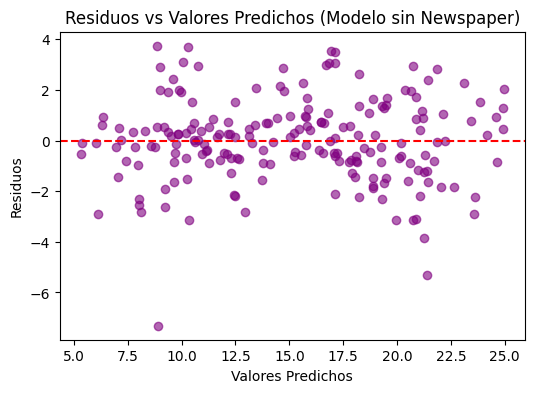

In [29]:
# 6.3 Gráfico de dispersión de residuos vs predichos
plt.figure(figsize=(6, 4))
plt.scatter(y_pred_limpio, residuos_limpios, alpha=0.6, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores Predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs Valores Predichos (Modelo sin Newspaper)")
plt.show()



Los residuos se dispersan de forma aleatoria alrededor de la línea horizontal del cero. No se observa un patrón claro, lo que indica que se cumple el supuesto de homocedasticidad (varianza constante de los errores).

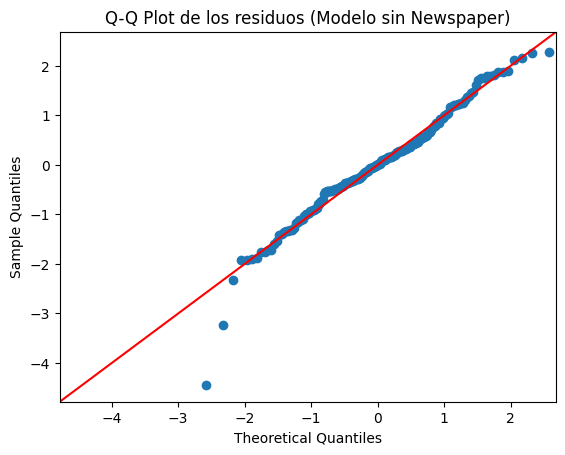

In [30]:
# 6.4 Gráfico Q-Q Plot
sm.qqplot(residuos_limpios, line='45', fit=True)
plt.title("Q-Q Plot de los residuos (Modelo sin Newspaper)")
plt.show()



Los puntos azules se alinean estrechamente sobre la línea roja. Solo hay ligeras desviaciones en los extremos, pero en terminos generales confirma que los residuos siguen una distribución normal.

In [31]:
# 6.5 Cálculo de métricas
mse_limpio = mean_squared_error(y, y_pred_limpio)
rmse_limpio = np.sqrt(mse_limpio)
r2_limpio = r2_score(y, y_pred_limpio)

print("Métricas del Modelo sin Newspaper:")
print(f"MSE: {mse_limpio:.2f}")
print(f"RMSE: {rmse_limpio:.2f}")
print(f"R²: {r2_limpio:.4f}")



Métricas del Modelo sin Newspaper:
MSE: 2.71
RMSE: 1.65
R²: 0.9026


El R² de 0.9026 nos dice que este modelo, usando únicamente TV y Radio, sigue siendo capaz de explicar el 90.26% de la varianza en las ventas.

El RMSE de 1.65 indica que el error promedio en nuestras predicciones es pequeño. Eliminar la variable "Newspaper" no afectó negativamente el rendimiento predictivo del modelo.

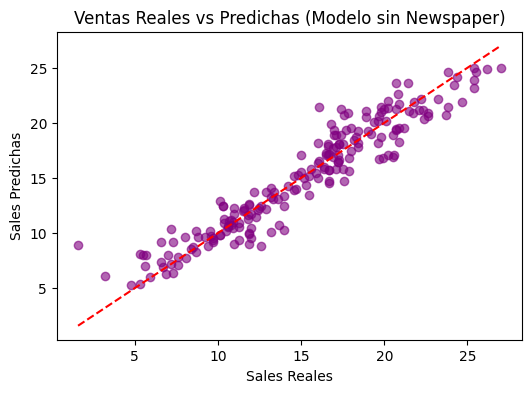

In [32]:
# 6.6 Gráfico de Sales reales vs Sales predichas
plt.figure(figsize=(6, 4))
plt.scatter(y, y_pred_limpio, alpha=0.6, color='purple')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--')
plt.xlabel("Sales Reales")
plt.ylabel("Sales Predichas")
plt.title("Ventas Reales vs Predichas (Modelo sin Newspaper)")
plt.show()



Se observa que los puntos de predicción están muy cerca de la línea roja, confirmando que las predicciones del modelo (basadas solo en TV y Radio) se ajustan de manera muy precisa a los valores reales de las ventas.

In [33]:
# 6.7 Ajuste usando statsmodels
X_clean_sm = sm.add_constant(X_clean)
modelo_limpio_sm = sm.OLS(y, X_clean_sm).fit()
print(modelo_limpio_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        22:51:56   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

Observando los valores en la columna P>|t|, vemos que tanto TV como Radio tienen un p-value de 0.000.

Conclusión: Ambos p-values son menores a 0.05, lo que confirma que las dos variables que dejamos en el modelo son estadísticamente significativas y tienen un impacto real en la predicción de las ventas.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

¿Cuál de los modelos construidos fue el mejor?
El Modelo de la Parte 6 (que solo usa TV y Radio) fue el mejor. Aunque las metricas de RMSE y R² de ambos modelos son casi identicas (~0.902), el segundo modelo es mjor debido al "Principio de Parsimonia", es mas simple y previene el sobreajuste al eliminar Newspaper, que solo aportaba ruido estadistico.

¿Cuál fue el atributo que más influencia tiene en las ventas?
La variable TV. Aunque el coeficiente de "Radio" parece ligeramente superior, la inversión en TV tiene una correlación directa del 0.90 con las ventas y es la que más reduce el nivel del error, convirtiéndola en el principal valor detras de las ventas.